<a href="https://colab.research.google.com/github/shubhamumap/ml-fa2/blob/main/shubhd084.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 32)
         id diagnosis  feature_1  feature_2  feature_3  feature_4  feature_5  \
0    842302         M      17.99      10.38     122.80     1001.0    0.11840   
1    842517         M      20.57      17.77     132.90     1326.0    0.08474   
2  84300903         M      19.69      21.25     130.00     1203.0    0.10960   
3  84348301         M      11.42      20.38      77.58      386.1    0.14250   
4  84358402         M      20.29      14.34     135.10     1297.0    0.10030   

   feature_6  feature_7  feature_8  ...  feature_21  feature_22  feature_23  \
0    0.27760     0.3001    0.14710  ...       25.38       17.33      184.60   
1    0.07864     0.0869    0.07017  ...       24.99       23.41      158.80   
2    0.15990     0.1974    0.12790  ...       23.57       25.53      152.50   
3    0.28390     0.2414    0.10520  ...       14.91       26.50       98.87   
4    0.13280     0.1980    0.10430  ...       22.54       16.67      152.20   

   feature_24  feat

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:44:44] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



================ MODEL PERFORMANCE COMPARISON ================
                 Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
         Decision Tree  0.929825   0.904762 0.904762  0.904762 0.924603
         Random Forest  0.973684   1.000000 0.928571  0.962963 0.992890
Support Vector Machine  0.973684   1.000000 0.928571  0.962963 0.994709
               XGBoost  0.964912   1.000000 0.904762  0.950000 0.990410


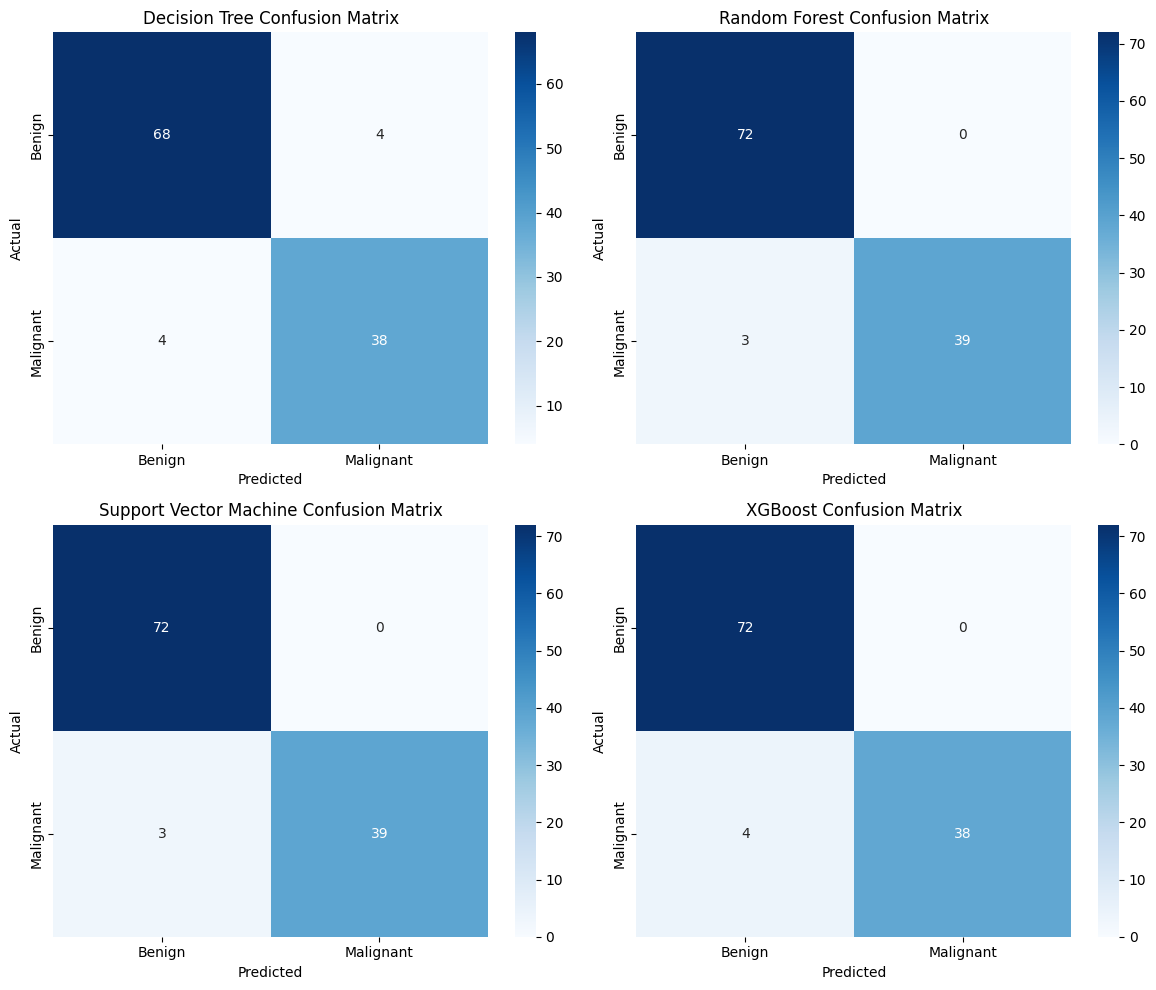

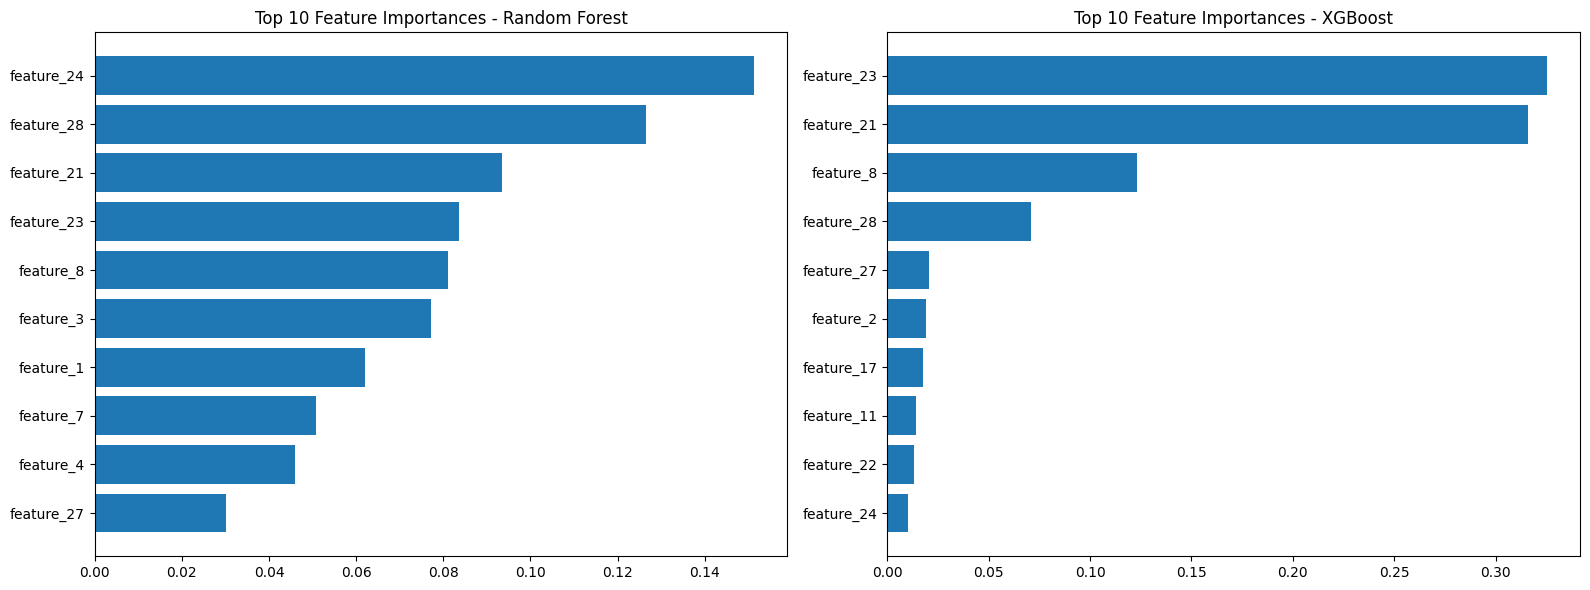

In [ ]:
# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# UCI WDBC Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# Define column names based on dataset documentation
columns = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]

# Load dataset
df = pd.read_csv(url, header=None, names=columns)
print(f"Dataset Shape: {df.shape}")
print(df.head())

# ==========================================
# 2. DATA PREPROCESSING
# ==========================================
# Drop unnecessary ID column
df = df.drop(columns=['id'])

# Encode target variable: Diagnosis ('M' -> 1, 'B' -> 0)
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])

# Separate features (X) and target (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Split into train and test sets (80% train, 20% test with stratification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling (Crucial for SVM, helpful for trees/boosting)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")

# ==========================================
# 3. MODEL TRAINING & EVALUATION
# ==========================================
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

results = []

for name, model in models.items():
    # Fit model (use scaled features for all models for consistency)
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

# Convert results to DataFrame
results_df = pd.DataFrame(results)
print("\n================ MODEL PERFORMANCE COMPARISON ================")
print(results_df.to_string(index=False))

# ==========================================
# 4. CONFUSION MATRICES VISUALIZATION
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'])
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# ==========================================
# 5. FEATURE IMPORTANCE (RANDOM FOREST & XGBOOST)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest Feature Importance
rf_importance = models["Random Forest"].feature_importances_
rf_indices = np.argsort(rf_importance)[-10:]
axes[0].barh(range(10), rf_importance[rf_indices], align='center')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels([X.columns[i] for i in rf_indices])
axes[0].set_title("Top 10 Feature Importances - Random Forest")

# XGBoost Feature Importance
xgb_importance = models["XGBoost"].feature_importances_
xgb_indices = np.argsort(xgb_importance)[-10:]
axes[1].barh(range(10), xgb_importance[xgb_indices], align='center')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([X.columns[i] for i in xgb_indices])
axes[1].set_title("Top 10 Feature Importances - XGBoost")

plt.tight_layout()
plt.show()